# 05 配置和API

把网络、采样器和优化器看作独立对象，再将正确对象传给Solver。API短例不需要大型训练。

默认仅运行 **smoke**；两轮训练只用于理解流程。把 `MODE` 改成 `reproduction` 才会按文档配置训练。

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Image

# 同时支持从项目根目录或 notebooks 目录启动。
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "请从项目目录打开 Notebook"
sys.path.insert(0, str(ROOT / "src"))
from ndeq_examples.runner import run, environment
MODE = "smoke"
SEED = 42
environment()

<PROJECT_ROOT>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.12.6',
 'platform': 'Windows-11-10.0.26200-SP0',
 'packages': {'torch': '2.6.0+cpu',
  'neurodiffeq': '0.7.0',
  'numpy': '1.26.4',
  'scipy': '1.15.2',
  'matplotlib': '3.9.2',
  'pandas': '2.2.3',
  'pillow': '10.4.0'},
 'neurodiffeq_module_version': '0.6.3-dev'}

## network

先预测图像的大致形状，再运行下面的共享实现。

network: smoke_passed; numerical_pass=False; <PROJECT_ROOT>\results\notebook_runs\20261012T072009_network_smoke_s42_default_36d9f3


{'max_abs': 6.390235506324983,
 'rmse': 3.9706850390051653,
 'relative_l2': 5.420589220587468,
 'initial_max_abs': 0.0,
 'condition_max_abs': 0.0,
 'residual_rmse': 3.6235275048374684,
 'residual_max_abs': 6.388552324883048,
 'per_component': [{'max_abs': 6.390235506324983,
   'rmse': 3.9706850390051653,
   'relative_l2': 5.420589220587468}],
 'reference': {'kind': 'analytic'},
 'test_size': 256,
 'test_seed': 20230403,
 'acceptance': {'relative_l2': 0.02,
  'max_abs': 0.03,
  'residual_rmse': 0.03,
  'condition_max_abs': 1e-08},
 'acceptance_checks': {'relative_l2': False,
  'max_abs': False,
  'residual_rmse': False,
  'condition_max_abs': True},
 'numerical_pass': False,
 'energy_max_drift': 20.41790668187451}

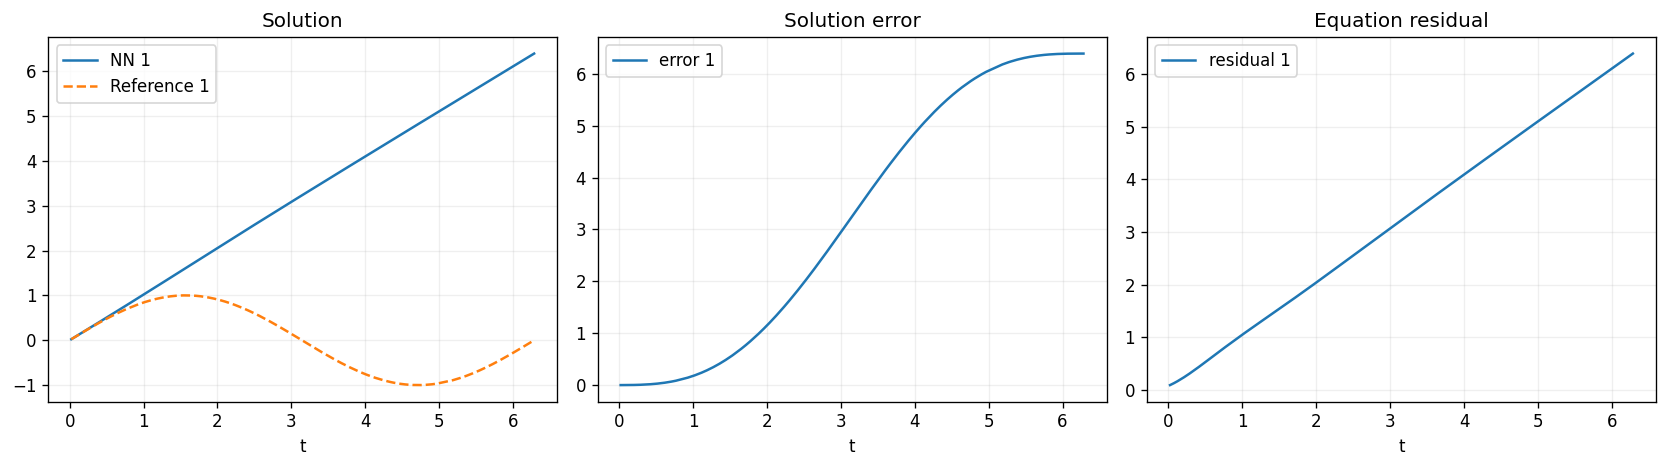

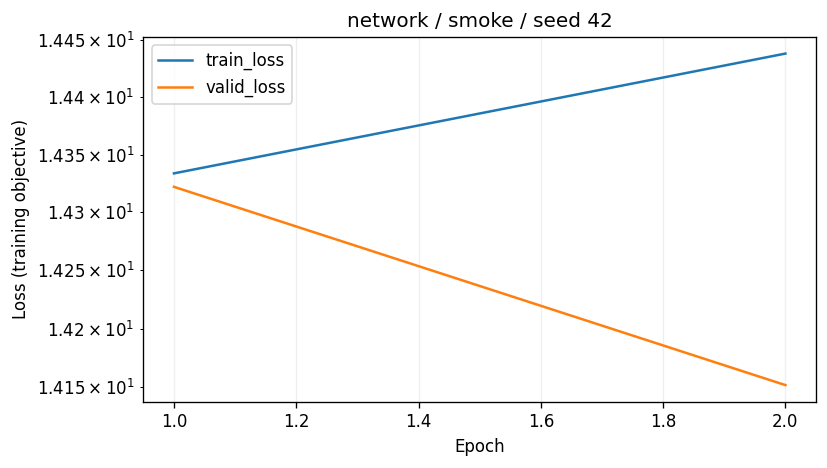

In [2]:
out = run("network", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

## sampling

先预测图像的大致形状，再运行下面的共享实现。

sampling: smoke_passed; numerical_pass=False; <PROJECT_ROOT>\results\notebook_runs\20261012T072012_sampling_smoke_s42_default_b07361


{'max_abs': 5.683208033765414,
 'rmse': 3.4633213345212597,
 'relative_l2': 4.7279605682449395,
 'initial_max_abs': 0.0,
 'condition_max_abs': 0.0,
 'residual_rmse': 3.1302446768491663,
 'residual_max_abs': 5.686885124194981,
 'per_component': [{'max_abs': 5.683208033765414,
   'rmse': 3.4633213345212597,
   'relative_l2': 4.7279605682449395}],
 'reference': {'kind': 'analytic'},
 'test_size': 256,
 'test_seed': 20230403,
 'acceptance': {'relative_l2': 0.02,
  'max_abs': 0.03,
  'residual_rmse': 0.03,
  'condition_max_abs': 1e-08},
 'acceptance_checks': {'relative_l2': False,
  'max_abs': False,
  'residual_rmse': False,
  'condition_max_abs': True},
 'numerical_pass': False,
 'energy_max_drift': 16.132305006582502}

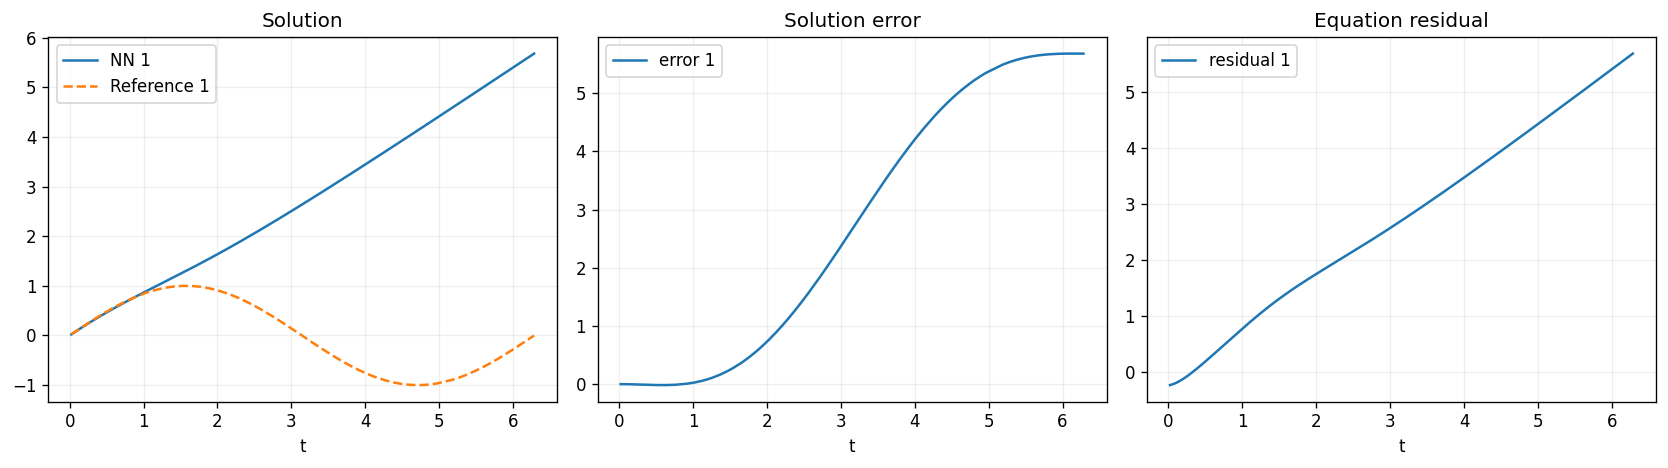

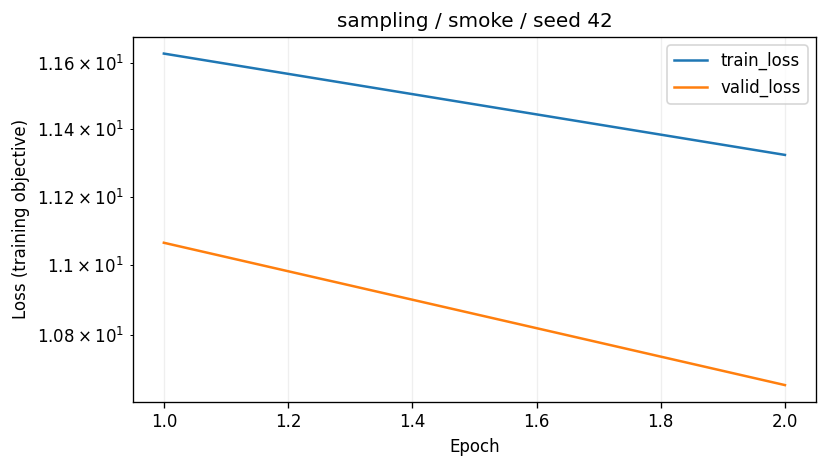

In [3]:
out = run("sampling", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

## optimizer

先预测图像的大致形状，再运行下面的共享实现。

optimizer: smoke_passed; numerical_pass=False; <PROJECT_ROOT>\results\notebook_runs\20261012T072013_optimizer_smoke_s42_default_de25e5


{'max_abs': 6.376732045821526,
 'rmse': 3.9607489004120704,
 'relative_l2': 5.407024879617858,
 'initial_max_abs': 0.0,
 'condition_max_abs': 0.0,
 'residual_rmse': 3.613622317743522,
 'residual_max_abs': 6.375120132082584,
 'per_component': [{'max_abs': 6.376732045821526,
   'rmse': 3.9607489004120704,
   'relative_l2': 5.407024879617858}],
 'reference': {'kind': 'analytic'},
 'test_size': 256,
 'test_seed': 20230403,
 'acceptance': {'relative_l2': 0.02,
  'max_abs': 0.03,
  'residual_rmse': 0.03,
  'condition_max_abs': 1e-08},
 'acceptance_checks': {'relative_l2': False,
  'max_abs': False,
  'residual_rmse': False,
  'condition_max_abs': True},
 'numerical_pass': False,
 'energy_max_drift': 20.331427870567353}

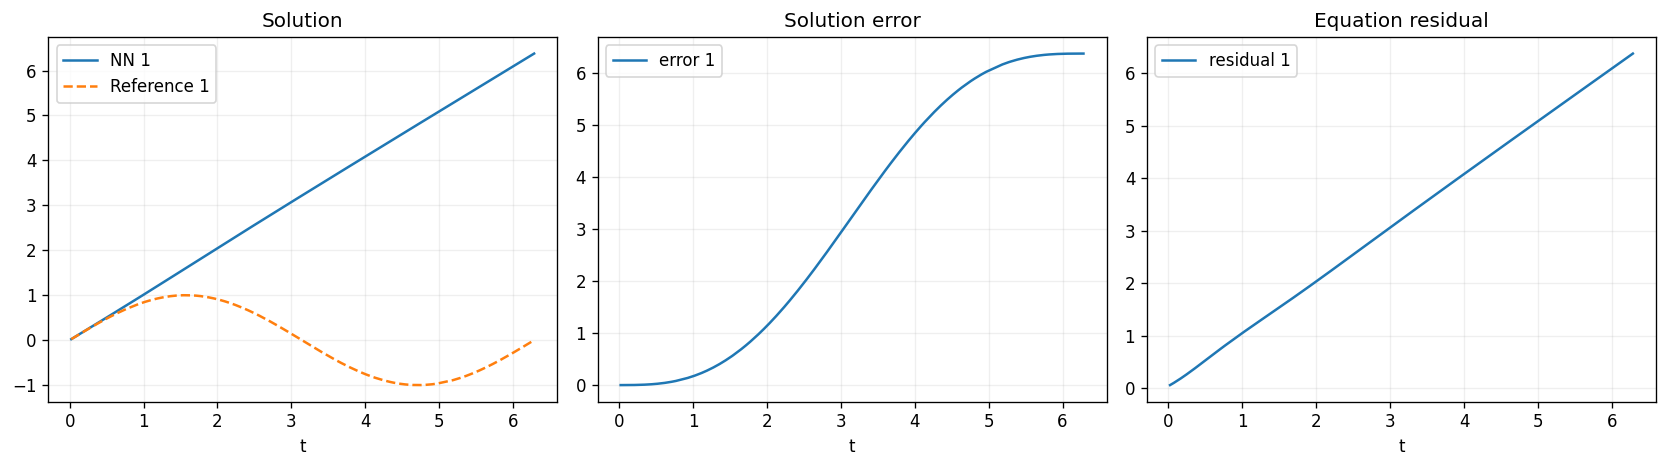

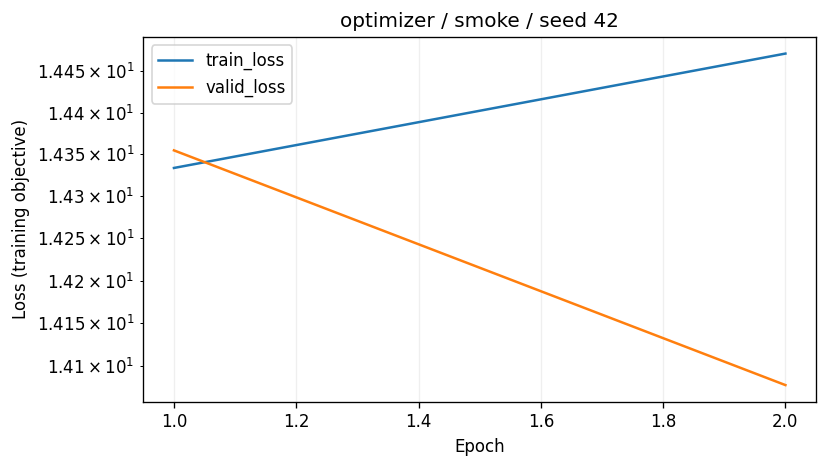

In [4]:
out = run("optimizer", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

## loss

先预测图像的大致形状，再运行下面的共享实现。

loss: smoke_passed; numerical_pass=False; <PROJECT_ROOT>\results\notebook_runs\20261012T072013_loss_smoke_s42_default_a35f5b


{'max_abs': 5.684728026839566,
 'rmse': 3.464179299093045,
 'relative_l2': 4.729131820425303,
 'initial_max_abs': 0.0,
 'condition_max_abs': 0.0,
 'residual_rmse': 3.1310434695153635,
 'residual_max_abs': 5.688367597786852,
 'per_component': [{'max_abs': 5.684728026839566,
   'rmse': 3.464179299093045,
   'relative_l2': 4.729131820425303}],
 'reference': {'kind': 'analytic'},
 'test_size': 256,
 'test_seed': 20230403,
 'acceptance': {'relative_l2': 0.02,
  'max_abs': 0.03,
  'residual_rmse': 0.03,
  'condition_max_abs': 1e-08},
 'acceptance_checks': {'relative_l2': False,
  'max_abs': False,
  'residual_rmse': False,
  'condition_max_abs': True},
 'numerical_pass': False,
 'energy_max_drift': 16.14117765070083}

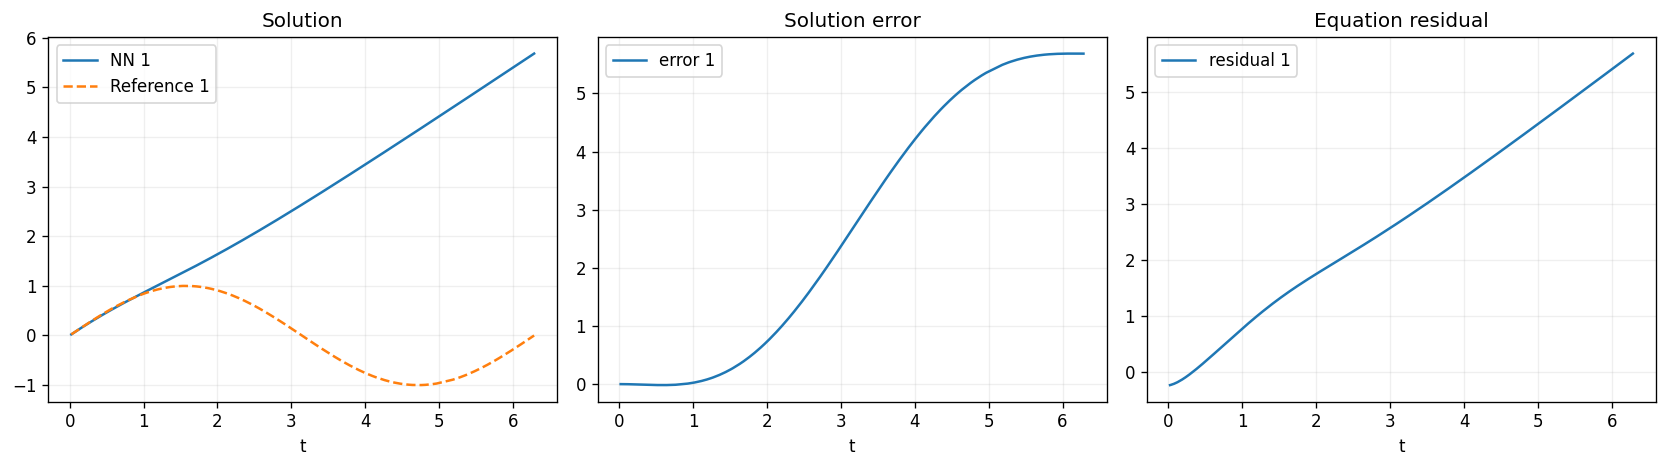

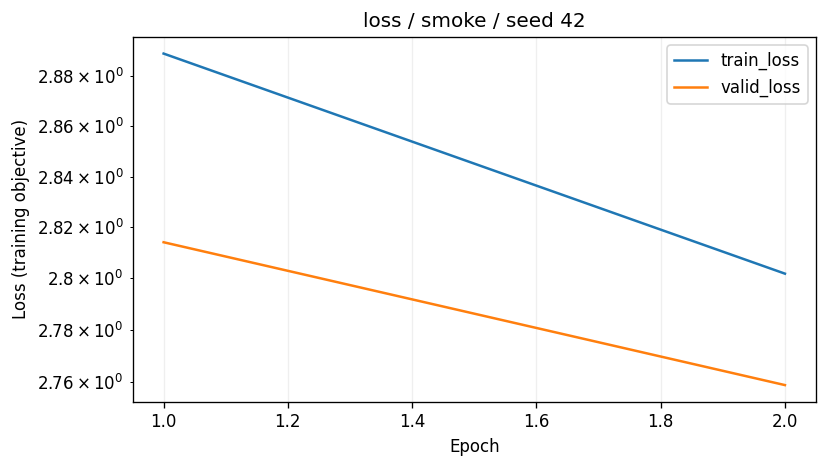

In [5]:
out = run("loss", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

## api_solution

先预测图像的大致形状，再运行下面的共享实现。

In [6]:
out = run("api_solution", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

<PROJECT_ROOT>\.venv\Lib\site-packages\neurodiffeq\monitors.py:590: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.pause(0.05)


<PROJECT_ROOT>\.venv\Lib\site-packages\neurodiffeq\monitors.py:771: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.pause(0.05)


api_solution: snippet_verified; numerical_pass=None; <PROJECT_ROOT>\results\notebook_runs\20261012T072014_api_solution_smoke_s42_default_dec003


{'checks_passed': True,
 'solution_calls': {'decay': {'shape': [16, 1], 'copy_isolated': True},
  'laplace': {'shape': [64, 1], 'copy_isolated': True}},
 'scope': '六处重复片段统一用 1D/2D 展示单坐标和多坐标调用；不宣称新增球面训练实验'}

## api_mesh

先预测图像的大致形状，再运行下面的共享实现。

In [7]:
out = run("api_mesh", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

api_mesh: snippet_verified; numerical_pass=None; <PROJECT_ROOT>\results\notebook_runs\20261012T072016_api_mesh_smoke_s42_default_bcbc70


{'checks_passed': True, 'mesh_shape': [27, 3], 'two_equivalences': True}

## api_callbacks

先预测图像的大致形状，再运行下面的共享实现。

In [8]:
out = run("api_callbacks", mode=MODE, seed=SEED, root=ROOT / "results/notebook_runs")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))
display(metrics)
for name in ("solution.png", "domain.png", "residual_lesson.png", "loss.png"):
    if (out / name).exists():
        display(Image(filename=str(out / name)))

api_callbacks: snippet_verified; numerical_pass=None; <PROJECT_ROOT>\results\notebook_runs\20261012T072016_api_callbacks_smoke_s42_default_33e11a


{'checks_passed': True,
 'truth_table_columns': ['a', 'b', 'c', 'and', 'or', 'not_a', 'xor'],
 'truth_table': [[False, False, False, False, False, True, False],
  [False, False, True, False, True, True, True],
  [False, True, False, False, True, True, True],
  [False, True, True, False, True, True, False],
  [True, False, False, False, True, False, True],
  [True, False, True, False, True, False, False],
  [True, True, False, False, True, False, False],
  [True, True, True, True, True, False, True]]}

## 自查

- 这里的未知函数和自变量分别是什么？
- 初始/边界条件如何施加？
- metrics里哪一项是方程残差，哪一项是解误差？
- 当前是流程验证，还是完整训练？

详细说明见 `docs/learning_guide_zh.md` 和 `docs/validation_protocol.md`。